# Ball tracking on a video

Run the trained heatmap model from `single_image_dataset.ipynb` on the selected volleyball clip.

The notebook:

1. loads `ball_model.pth`;
2. resizes each frame to the model's `512 × 288` input;
3. maps the predicted ball coordinate back to the video's native resolution;
4. writes an annotated MP4 and a per-frame CSV.

`CONFIDENCE_THRESHOLD` is a tunable heatmap cutoff. Lower it if valid balls are being skipped; raise it if false detections are being drawn.

In [1]:
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Video, display
from tqdm import tqdm

working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate
    for candidate in (working_dir, *working_dir.parents)
    if (candidate / "model" / "cnn.py").exists()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model.cnn import CNN

VIDEO_PATH = Path(
    "/home/bugslayer/Documents/research/data/VolleyVision/VballNet/test/20250623_beach/video/beach_st_lenina_20250622_g1_008.mp4"
)
MODEL_PATH = PROJECT_ROOT / "notebooks" / "dataset" / "ball_model.pth"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "dataset" / "outputs"

MODEL_WIDTH = 512
MODEL_HEIGHT = 288
CONFIDENCE_THRESHOLD = 0.10

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_VIDEO_PATH = OUTPUT_DIR / f"{VIDEO_PATH.stem}_ball_tracking.mp4"
OUTPUT_CSV_PATH = OUTPUT_DIR / f"{VIDEO_PATH.stem}_ball_detections.csv"

In [2]:
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Model checkpoint not found: {MODEL_PATH}")

capture = cv2.VideoCapture(str(VIDEO_PATH))
if not capture.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

source_width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
source_height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
source_fps = float(capture.get(cv2.CAP_PROP_FPS))
frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
capture.release()

if source_width <= 0 or source_height <= 0:
    raise RuntimeError("The video reports an invalid frame size.")

if source_fps <= 0:
    source_fps = 30.0

video_info = pd.Series(
    {
        "path": str(VIDEO_PATH),
        "resolution": f"{source_width} × {source_height}",
        "fps": source_fps,
        "frames": frame_count,
        "duration_seconds": frame_count / source_fps if frame_count else None,
    },
    name="value",
).to_frame()

display(video_info)

,value
path,/home/bugslayer/Documents/research/data/Volley...
resolution,1920 × 1080
fps,29.97003
frames,490
duration_seconds,16.349667


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN().to(device)
state_dict = torch.load(MODEL_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

print(f"Loaded {MODEL_PATH.name} on {device}.")

Loaded ball_model.pth on cuda.


In [4]:
def preprocess_frame(frame_bgr):
    resized_bgr = cv2.resize(
        frame_bgr,
        (MODEL_WIDTH, MODEL_HEIGHT),
        interpolation=cv2.INTER_AREA,
    )
    resized_rgb = cv2.cvtColor(resized_bgr, cv2.COLOR_BGR2RGB)
    tensor = (
        torch.from_numpy(resized_rgb)
        .permute(2, 0, 1)
        .float()
        .div(255.0)
        .unsqueeze(0)
        .to(device)
    )
    return tensor


@torch.inference_mode()
def predict_ball(frame_bgr):
    heatmap = model(preprocess_frame(frame_bgr))[0, 0].float().cpu()

    flat_index = int(heatmap.argmax().item())
    model_y, model_x = divmod(flat_index, MODEL_WIDTH)
    confidence = float(heatmap[model_y, model_x].item())

    frame_height, frame_width = frame_bgr.shape[:2]
    x = round(model_x * (frame_width - 1) / (MODEL_WIDTH - 1))
    y = round(model_y * (frame_height - 1) / (MODEL_HEIGHT - 1))

    return {
        "x": int(x),
        "y": int(y),
        "confidence": confidence,
        "detected": confidence >= CONFIDENCE_THRESHOLD,
    }


def annotate_frame(frame_bgr, prediction):
    annotated = frame_bgr.copy()
    confidence = prediction["confidence"]

    if prediction["detected"]:
        center = (prediction["x"], prediction["y"])
        cv2.circle(annotated, center, 12, (0, 0, 0), 5, cv2.LINE_AA)
        cv2.circle(annotated, center, 12, (0, 255, 255), 2, cv2.LINE_AA)
        label = f"ball {confidence:.3f}"
        label_origin = (max(10, center[0] + 16), max(30, center[1] - 16))
        cv2.putText(
            annotated,
            label,
            label_origin,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 0, 0),
            4,
            cv2.LINE_AA,
        )
        cv2.putText(
            annotated,
            label,
            label_origin,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 255),
            2,
            cv2.LINE_AA,
        )

    return annotated

{'x': 946, 'y': 462, 'confidence': 0.9882914423942566, 'detected': True}


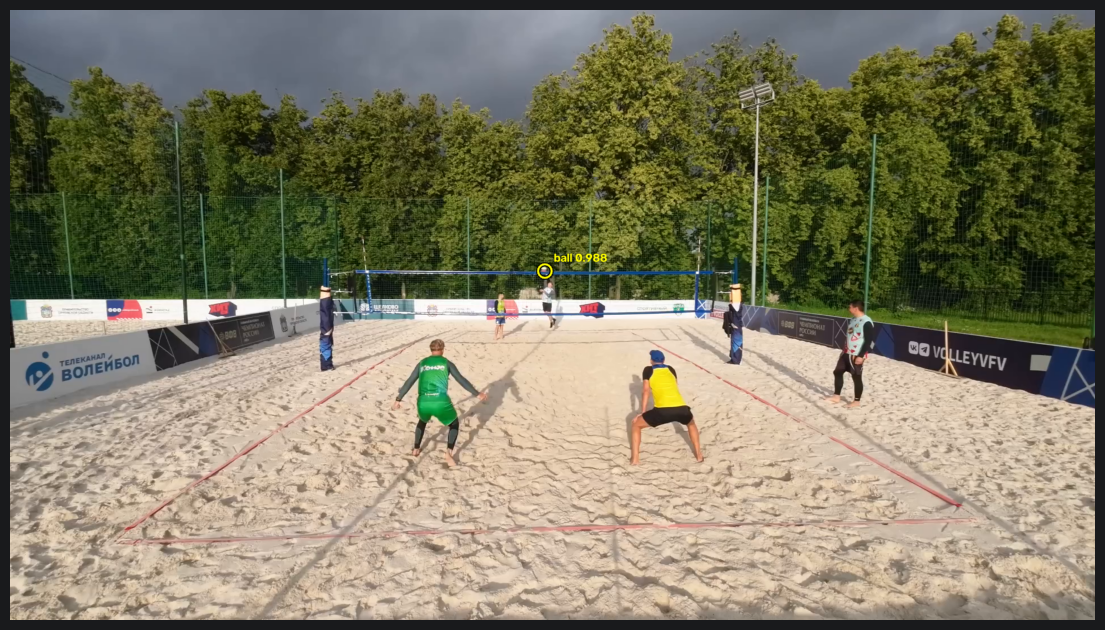

In [5]:
capture = cv2.VideoCapture(str(VIDEO_PATH))
ok, first_frame = capture.read()
capture.release()

if not ok:
    raise RuntimeError("Could not read the first video frame.")

first_prediction = predict_ball(first_frame)
first_annotated = annotate_frame(first_frame, first_prediction)

print(first_prediction)
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(first_annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [6]:
capture = cv2.VideoCapture(str(VIDEO_PATH))
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    source_fps,
    (source_width, source_height),
)

if not capture.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

if not writer.isOpened():
    capture.release()
    raise RuntimeError(f"Could not create output video: {OUTPUT_VIDEO_PATH}")

detections = []
frame_index = 0

try:
    with tqdm(total=frame_count or None, desc="Running inference", unit="frame") as progress:
        while True:
            ok, frame = capture.read()
            if not ok:
                break

            prediction = predict_ball(frame)
            detections.append(
                {
                    "frame_index": frame_index,
                    "timestamp_seconds": frame_index / source_fps,
                    **prediction,
                }
            )
            writer.write(annotate_frame(frame, prediction))

            frame_index += 1
            progress.update(1)
finally:
    capture.release()
    writer.release()

detections_df = pd.DataFrame(detections)
detections_df.to_csv(OUTPUT_CSV_PATH, index=False)

print(f"Wrote {frame_index} frames to {OUTPUT_VIDEO_PATH}")
print(f"Wrote detections to {OUTPUT_CSV_PATH}")
display(detections_df.head())

Running inference: 100%|██████████| 490/490 [00:15<00:00, 32.09frame/s]

Wrote 490 frames to /home/bugslayer/Documents/research/VolleyVision/notebooks/dataset/outputs/beach_st_lenina_20250622_g1_008_ball_tracking.mp4
Wrote detections to /home/bugslayer/Documents/research/VolleyVision/notebooks/dataset/outputs/beach_st_lenina_20250622_g1_008_ball_detections.csv


,frame_index,timestamp_seconds,x,y,confidence,detected
0,0,0.000000,946,462,0.988291,True
1,1,0.033367,943,451,0.959124,True
2,2,0.066733,939,451,0.987258,True
3,3,0.100100,939,447,0.983259,True
4,4,0.133467,935,444,1.009477,True


In [7]:
display(Video(str(OUTPUT_VIDEO_PATH), embed=False, width=960))